<a href="https://colab.research.google.com/github/juanvazquez-analyst/analisis-ventas/blob/main/Analisis_ventas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de ventas

## Objetivo
Analizar las ventas semanales para identificar tendencias y productos destacados.

## Datos
Se utilizan datos simulados.

## Herramientas
Python, pandas, sqlite3 y matplotlib.

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
print("Importaciones realizadas efectivamente")

Importaciones realizadas efectivamente


# - Carga de datos:
La Base de Datos proviene de un archivo de Excel con ventas simuladas.

In [74]:
#Subimos el archivo
url = "https://github.com/juanvazquez-analyst/analisis-ventas/raw/main/VentasSimuladas.xlsx"
df=pd.read_excel(url)

In [75]:
#Cargamos la Base de Datos VentasSimuladas.xlsx y la convertimos a .db

#Leer Excel
df=pd.read_excel("VentasSimuladas.xlsx")

#Crear base de datos SQLite
conexion=sqlite3.connect("ventas.db")

#Guardar datos en una tabla
df.to_sql("tabla_datos", conexion, if_exists="replace", index=False)
conexion.close()
print("Conversión completada")

Conversión completada


#- Exploración:
Muestro las primeras filas, el tamaño del conjunto y los tipos de columnas.

In [76]:
#Creamos función para realizar consultas
def consulta(query):
  conexion=sqlite3.connect("ventas.db")
  df_consulta=pd.read_sql_query(query, conexion)
  conexion.close()
  return df_consulta

#Consultamos las primeras 5 filas
query= """
SELECT
 *
FROM
 tabla_datos
LIMIT
 5
"""
consulta(query)

,index,ColFecha,ColCajero,ColProducto,ColPrecio,ColCantidad,ColTotal,ColSucursal
0,0,2025-01-01,Valeria Jiménez Flores,Agenda anual,5050.65,87,439406.55,Reforma
1,1,2025-01-01,Diana Carolina Salazar Ruiz,Caja de grapas,5863.65,20,117273.00,Santa Fe
2,2,2025-01-01,Paola Alejandra Vargas León,Corrector líquido,7064.61,69,487458.09,Xochimilco
3,3,2025-01-01,José Luis González Cruz,Carpeta tamaño carta,152.38,87,13257.06,Polanco
4,4,2025-01-01,Ana Sofía Morales García,Marcador para pizarrón,1049.47,95,99699.65,Reforma


In [77]:
#Tamaño del conjunto
df=consulta("SELECT * FROM tabla_datos")
print("Filas y columnas:", df.shape)

Filas y columnas: (131676, 8)


In [78]:
#Tipos de columnas
df.dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131676 entries, 0 to 131675
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   index        131676 non-null  int64  
 1   ColFecha     131676 non-null  object 
 2   ColCajero    131676 non-null  object 
 3   ColProducto  131676 non-null  object 
 4   ColPrecio    131676 non-null  float64
 5   ColCantidad  131676 non-null  int64  
 6   ColTotal     131676 non-null  float64
 7   ColSucursal  131676 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 8.0+ MB


#-Limpieza:
Eliminamos filas con valor NULL

In [79]:
#Creamos una función que modifique la base
def ejecutar(sql):
    conexion = sqlite3.connect("ventas.db")
    cursor = conexion.cursor()
    cursor.execute(sql)
    filas = cursor.rowcount
    conexion.commit()
    conexion.close()
    return filas

#Filas antes de agregar datos NULL
consulta("SELECT COUNT(*) AS total_filas FROM tabla_datos")

,total_filas
0,131676


In [80]:
#Agrgamos registros NULL
for _ in range(3):
    ejecutar("INSERT INTO tabla_datos DEFAULT VALUES")

#Filas despues de agregar datos NUll
consulta("SELECT * FROM tabla_datos ORDER BY rowid DESC LIMIT 5")

,index,ColFecha,ColCajero,ColProducto,ColPrecio,ColCantidad,ColTotal,ColSucursal
0,NaN,None,None,None,NaN,NaN,NaN,None
1,NaN,None,None,None,NaN,NaN,NaN,None
2,NaN,None,None,None,NaN,NaN,NaN,None
3,11590.0,2025-01-07,Juan Carlos Ramírez López,Tijeras escolares,1115.79,38.0,42400.02,Xochimilco
4,11589.0,2025-01-07,Miguel Ángel Torres Hernández,Juego de geometría,5486.79,95.0,521245.05,San Ángel


In [81]:
#Armo la condición "todas las columnas son NULL"
columnas = consulta("PRAGMA table_info(tabla_datos)")["name"].tolist()
condicion = " AND ".join(f'"{c}" IS NULL' for c in columnas)
print(condicion)
#Contamos las filas NULL
consulta(f"SELECT COUNT(*) AS filas_nulas FROM tabla_datos WHERE {condicion}")

"index" IS NULL AND "ColFecha" IS NULL AND "ColCajero" IS NULL AND "ColProducto" IS NULL AND "ColPrecio" IS NULL AND "ColCantidad" IS NULL AND "ColTotal" IS NULL AND "ColSucursal" IS NULL


,filas_nulas
0,3


In [82]:
#Borramos las filas NULL
borradas = ejecutar(f"DELETE FROM tabla_datos WHERE {condicion}")
print("Filas eliminadas:", borradas)

#Verificamos total_filas = 131676
consulta("SELECT COUNT(*) AS total_filas FROM tabla_datos")

Filas eliminadas: 3


,total_filas
0,131676


#-Análisis:
Calculamos los 3 productos mas vendidos, las 3 sucursales que mas venideron y los empleados que mas vendieron el ultimo día de la semana.

In [83]:
#Top 3 Productos mas vendidos
query= """
SELECT
 colProducto,
 ---Cambiamos el nombre de la tabla
 SUM(colCantidad) AS Total_vendido
FROM
 tabla_datos
GROUP BY
 colProducto
ORDER BY
 colCantidad
LIMIT
 3
"""
consulta(query)

,ColProducto,Total_vendido
0,Clips metálicos,128677
1,Papel fotográfico,130311
2,Calculadora científica,127923


In [84]:
#Top 3 sucursales que mas vendieron
query= """
SELECT
 colSucursal,
 ---Convertimos números a texto
 CAST(SUM(colTotal) AS TEXT) AS Suma_Total
FROM
 tabla_datos
GROUP BY
 colSucursal
ORDER BY
 colTotal
LIMIT
 3
"""
consulta(query)

,ColSucursal,Suma_Total
0,Coyoacán,3368036153.15
1,Tlalpan,3289506334.15
2,Polanco,3252236786.62


In [85]:
#Top 3 empleados que vendieron entre $50,000 y $58,000 el ultimo día de la semana
query= """
SELECT
 colCajero,
 CAST(SUM(colCantidad) AS TEXT) AS Total,
 colFecha
FROM
 tabla_datos
WHERE
 colFecha = "2025-01-07"
GROUP BY
 colCajero
HAVING
 SUM(colCantidad) BETWEEN 50000 AND 58000
ORDER BY
 SUM(colCantidad) DESC
LIMIT
 3
"""
consulta(query)

,ColCajero,Total,ColFecha
0,Paola Alejandra Vargas León,57947,2025-01-07
1,Miguel Ángel Torres Hernández,57628,2025-01-07
2,Luis Fernando Ortega Díaz,57620,2025-01-07


#-Visualización:
Generamos dos graficos:
- Ventas totales por sucursal
- Ventas totales por día

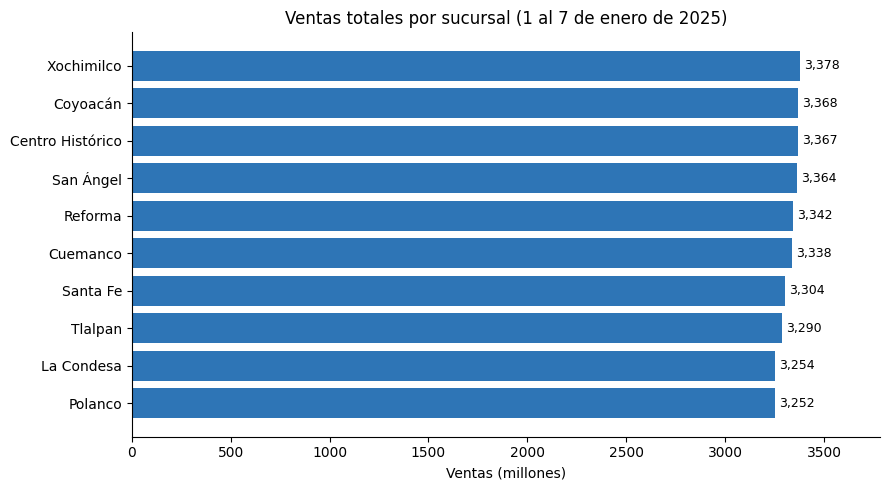

In [86]:
#Ventas totales por sucursal
df_suc = consulta("""
SELECT
 ColSucursal,
 SUM(ColTotal) AS Total
FROM
 tabla_datos
GROUP BY
 ColSucursal
ORDER BY
 Total ASC
""")

#Creamos una columna nueva con el total en millones para que los números de la gráfica sean más cortos y legibles
df_suc["Total_M"] = df_suc["Total"] / 1_000_000

#Creamos la figura (el lienzo) y los ejes (el área donde se dibuja); figsize es el tamaño en pulgadas (ancho, alto)
fig, ax = plt.subplots(figsize=(9, 5))

#Dibujamos barras horizontales: eje Y = sucursales, longitud de cada barra = ventas en millones; color azul
barras = ax.barh(df_suc["ColSucursal"], df_suc["Total_M"], color="#2E75B6")

#Escribimos el valor al final de cada barra, con separador de miles y sin decimales (:,.0f)
#padding separa el texto de la barra y fontsize define el tamaño de letra
ax.bar_label(barras, labels=[f"{v:,.0f}" for v in df_suc["Total_M"]], padding=3, fontsize=9)

#Título de la gráfica y nombre del eje horizontal (indica la unidad)
ax.set_title("Ventas totales por sucursal (1 al 7 de enero de 2025)")
ax.set_xlabel("Ventas (millones)")

#El eje X empieza en 0 y llega al máximo + 12% para que quepa el texto de la barra más larga
ax.set_xlim(0, df_suc["Total_M"].max() * 1.12)

#Ocultamos el borde superior y el derecho para que la gráfica se vea más limpia
ax.spines[["top", "right"]].set_visible(False)

#Ajusta los márgenes para que nada quede cortado y muestra la gráfica
plt.tight_layout()
plt.show()

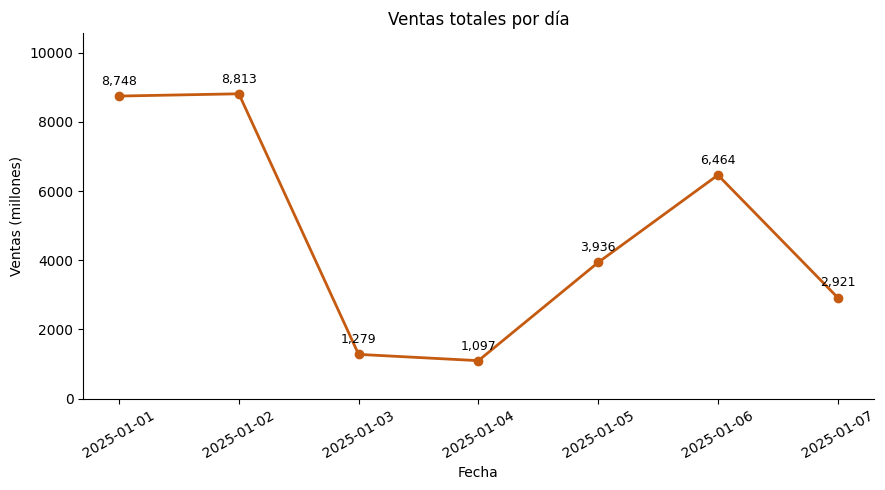

In [87]:
#Ventas totales por día
df_dia = consulta("""
SELECT ColFecha, SUM(ColTotal) AS Total
FROM tabla_datos
GROUP BY ColFecha
ORDER BY ColFecha
""")

#Columna nueva con el total en millones para que los números sean más legibles
df_dia["Total_M"] = df_dia["Total"] / 1_000_000

#Creamos la figura (lienzo) y los ejes (área de dibujo) con tamaño 9x5 pulgadas
fig, ax = plt.subplots(figsize=(9, 5))

#Dibujamos la línea: eje X = fechas, eje Y = ventas en millones
#marker="o" pone un punto en cada día, color naranja y linewidth es el grosor de la línea
ax.plot(df_dia["ColFecha"], df_dia["Total_M"], marker="o", color="#C55A11", linewidth=2)

#Recorremos cada punto (fecha, valor) para escribir su valor encima del punto
#xytext=(0, 8) lo sube 8 puntos y ha="center" lo centra; :,.0f le da formato de miles sin decimales
for x, y in zip(df_dia["ColFecha"], df_dia["Total_M"]):
    ax.annotate(f"{y:,.0f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

#Título de la gráfica y nombres de los ejes
ax.set_title("Ventas totales por día")
ax.set_xlabel("Fecha")
ax.set_ylabel("Ventas (millones)")

#El eje Y empieza en 0 y llega al máximo + 20% para dejar espacio a los números sobre los puntos
ax.set_ylim(0, df_dia["Total_M"].max() * 1.2)

#Ocultamos el borde superior y el derecho para que la gráfica se vea más limpia
ax.spines[["top", "right"]].set_visible(False)

#Giramos las fechas del eje X 30 grados para que no se encimen
plt.xticks(rotation=30)

#Ajusta los márgenes para que nada quede cortado y muestra la gráfica
plt.tight_layout()
plt.show()

#-Conclusiones:
Como podemos observar la gráfica de "Ventas por sucursal", nos muestra que en todas las sucrsales vendieron casi la misma cantida. Lo que indica que los procesos de venta dan los resultados esperados.

En el otro grafico se muestra los dos días de menor rendiemiento de todas las sucursales en general, que serían los dias:
- "2025-01-03"
- "2025-01-04"